In [ ]:
# conda env tabpfn_env

In [ ]:
# # Install sklearn
# ! pip install scikit-learn==1.5.2

# # Install TabPFN API Client
# ! pip install tabpfn-client

# # TabPFN Extensions installs optional functionalities around the TabPFN model
# # These include post-hoc ensembles, interpretability tools, and more
# ! git clone https://github.com/PriorLabs/tabpfn-extensions
# ! pip install -e tabpfn-extensions
# ! pip install tabpfn # TabPFN, currently required by tabpfn-extensions, but not basic usage


# # Install Baselines
# ! pip install catboost xgboost

# # Install example datasets
# ! pip install datasets

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [16]:
import tabpfn_client

In [18]:
# TabPFN Imports
from tabpfn_client import init, TabPFNClassifier, TabPFNRegressor

token = 'YOUR_TABPFN_TOKEN'

tabpfn_client.set_access_token(token)

In [19]:
# Load dataset
df = pd.read_csv("./DataSet_Encoded_DriveCycles.csv")

In [20]:
pd.DataFrame(df).head()

,w1,w2,w3,wPL,DC,range
0,0.19,0.63,0.94,0.000029,NEDC_extended,168.577083
1,0.43,0.69,0.95,0.000073,FHDS_extended,193.161944
2,0.62,0.12,0.12,0.000062,US06HW_extended,125.559007
3,0.53,0.65,0.41,0.000032,FUDSfast_extended,98.348028
4,0.41,0.44,0.18,0.000074,US06City_extended,134.261982


In [21]:
X = df[['w1', 'w2', 'w3', 'wPL', 'DC']].values
y = df['range'].values

X

array([[0.19, 0.63, 0.94, 2.9e-05, 'NEDC_extended'],
       [0.43, 0.69, 0.95, 7.3e-05, 'FHDS_extended'],
       [0.62, 0.12, 0.12, 6.2e-05, 'US06HW_extended'],
       ...,
       [0.92, 0.35, 0.22, 7.5e-05, 'NEDC_extended'],
       [0.95, 0.54, 0.54, 7.3e-05, 'FHDS_extended'],
       [0.22, 0.13, 0.31, 4.1e-05, 'FUDS_extended']],
      shape=(702, 5), dtype=object)

In [6]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,NEDC_extended
1,0.43,0.69,0.95,0.000073,FHDS_extended
2,0.62,0.12,0.12,0.000062,US06HW_extended
3,0.53,0.65,0.41,0.000032,FUDSfast_extended
4,0.41,0.44,0.18,0.000074,US06City_extended


In [22]:
# extracting 4th column from X

pd.DataFrame(X[:, 4]).head()

,0
0,NEDC_extended
1,FHDS_extended
2,US06HW_extended
3,FUDSfast_extended
4,US06City_extended


In [27]:
# encoding the 4th column

X[:, 4] = pd.Categorical(X[:, 4]).codes

In [9]:
pd.Series(X[:, 4]).value_counts()

1    102
3    100
0    100
5    100
2    100
4    100
6    100
Name: count, dtype: int64

In [23]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,NEDC_extended
1,0.43,0.69,0.95,0.000073,FHDS_extended
2,0.62,0.12,0.12,0.000062,US06HW_extended
3,0.53,0.65,0.41,0.000032,FUDSfast_extended
4,0.41,0.44,0.18,0.000074,US06City_extended


In [28]:
# comparing the original and encoded values and making a df which contains the original and encoded values for each unique value

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates()

# make a CSV for this DF which is printed

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates().to_csv('Encoded_DC.csv', index=False)


In [29]:
# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [30]:
model = TabPFNRegressor()

In [31]:
# Fit the model on the training data
model.fit(X_train, y_train)

TabPFNRegressor()

In [32]:
# Predict on both training and testing sets
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

Processing: 100%|██████████| [00:04<00:00]
Processing: 100%|██████████| [00:01<00:00]


In [33]:
# Evaluate model performance using RMSE and R²
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)

In [34]:
print("Training RMSE: {:.2f}".format(train_rmse))
print("Test RMSE: {:.2f}".format(test_rmse))
print("Training R²: {:.2f}".format(train_r2))
print("Test R²: {:.2f}".format(test_r2))

Training RMSE: 14.68
Test RMSE: 15.45
Training R²: 0.66
Test R²: 0.56


In [36]:
# Example prediction using the first row of the dataset
example_input = X[0:1]
example_prediction = model.predict(example_input)
print("\nExample prediction:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))

Processing: 100%|██████████| [00:01<00:00]


Example prediction:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.66
Actual range: 168.58


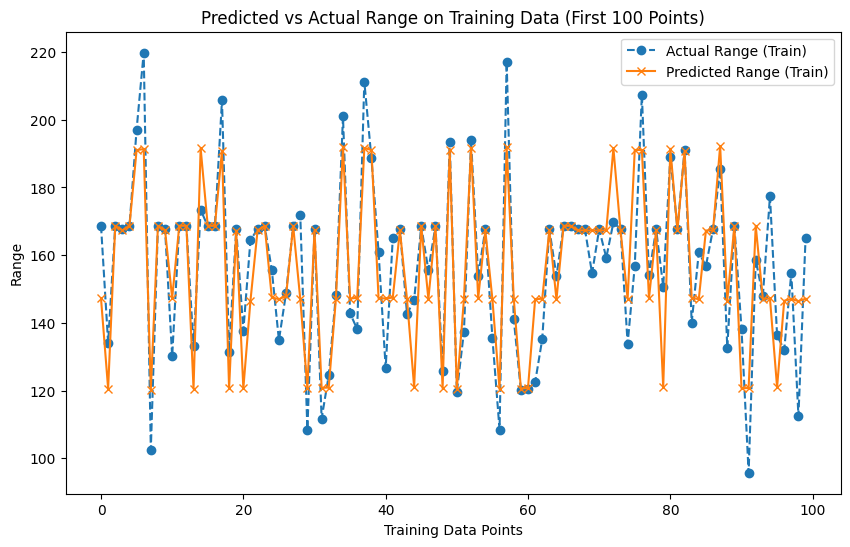

In [37]:
# Plot predicted vs. actual values for the first 100 training data points
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

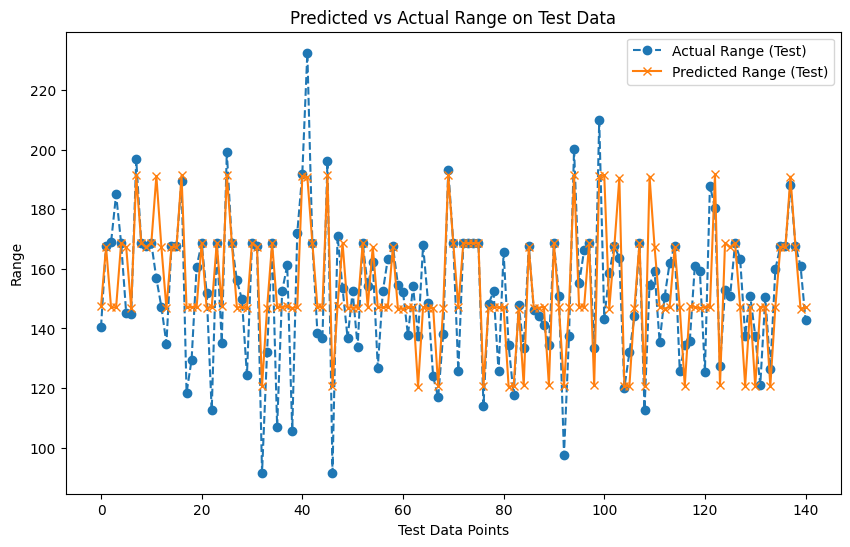

In [38]:
# Plot predicted vs. actual values for test data
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds, label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data')
plt.legend()
plt.show()

In [39]:
dc_categories = pd.Categorical(df['DC']).categories

In [40]:
def predict_range(w1, w2, w3, wPL, DC):
    """
    Predict the range using a single new sample.
    The DC value is encoded using the unique categories from the original dataset.
    """
    # Encode DC using the same categories from training data.
    # If the provided DC value isn't in the training categories, this will yield -1.
    dc_code = pd.Categorical([DC], categories=dc_categories).codes[0]
    # Create a 2D array of the new sample.
    input_sample = np.array([[w1, w2, w3, wPL, dc_code]])
    # Predict using the trained TabPFN regressor.
    prediction = model.predict(input_sample)
    return prediction[0]

In [41]:
# -------------------------------
# Test the predict_range function with the first row of the dataset
# -------------------------------
example_input = X[0:1]  # First row (already encoded)
example_prediction = model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))

Processing: 100%|██████████| [00:01<00:00]



Direct example prediction from model:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.66
Actual range: 168.58


In [44]:
raw_DC_value = df['DC'].iloc[0]
pred_from_func = predict_range(
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)
print("\nExample prediction using predict_range function:")
print("Predicted range: {:.2f}".format(pred_from_func))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))

Processing: 100%|██████████| [00:01<00:00]


Example prediction using predict_range function:
Predicted range: 168.65
Actual range: 168.58


In [45]:
import pickle

In [48]:
# -------------------------------
# Save the trained model using pickle
# -------------------------------
with open("./Models/tabpfn_regressor.pkl", "wb") as f:
    pickle.dump(model, f)
print("Model saved to tabpfn_regressor.pkl")

Model saved to tabpfn_regressor.pkl


In [49]:
# -------------------------------
# Load the model from disk
# -------------------------------
with open("./Models/tabpfn_regressor.pkl", "rb") as f:
    loaded_model = pickle.load(f)
print("Model loaded from tabpfn_regressor.pkl")

Model loaded from tabpfn_regressor.pkl


In [59]:
example_prediction = loaded_model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))

Processing: 100%|██████████| [00:01<00:00]


Direct example prediction from model:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.66
Actual range: 168.58


In [50]:
# Evaluate the loaded model on the test set to verify it works the same
loaded_test_preds = loaded_model.predict(X_test)
loaded_test_rmse = np.sqrt(mean_squared_error(y_test, loaded_test_preds))
loaded_test_r2   = r2_score(y_test, loaded_test_preds)

print("Loaded Model Test RMSE: {:.2f}".format(loaded_test_rmse))
print("Loaded Model Test R²: {:.2f}".format(loaded_test_r2))


Processing: 100%|██████████| [00:01<00:00]

Loaded Model Test RMSE: 15.47
Loaded Model Test R²: 0.56


In [53]:
def predict_range_model(model_instance, w1, w2, w3, wPL, DC):
    """
    Predict the range for a single new sample.
    The DC value is encoded using the original dataset's unique categories.
    """
    # Encode the provided DC value to its corresponding numeric code
    dc_code = pd.Categorical([DC], categories=dc_categories).codes[0]
    # Create a 2D array for the new sample
    input_sample = np.array([[w1, w2, w3, wPL, dc_code]])
    # Use the provided model instance to predict
    prediction = model_instance.predict(input_sample)
    return prediction[0]

In [51]:
example_input = X[0:1]  # Already encoded sample from the original dataset
raw_DC_value = df['DC'].iloc[0]  # Original DC value

In [52]:
# Direct prediction from the loaded model for comparison
direct_prediction = loaded_model.predict(example_input)[0]

Processing: 100%|██████████| [00:01<00:00]


In [54]:
# Prediction using our helper function
func_prediction = predict_range_model(
    loaded_model,
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)

Processing: 100%|██████████| [00:01<00:00]


In [55]:
print("\nDirect prediction from loaded model:")
print("Predicted range: {:.2f}".format(direct_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct prediction from loaded model:
Predicted range: 168.65
Actual range: 168.58


In [56]:
print("\nPrediction using predict_range_model function:")
print("Predicted range: {:.2f}".format(func_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Prediction using predict_range_model function:
Predicted range: 168.64
Actual range: 168.58


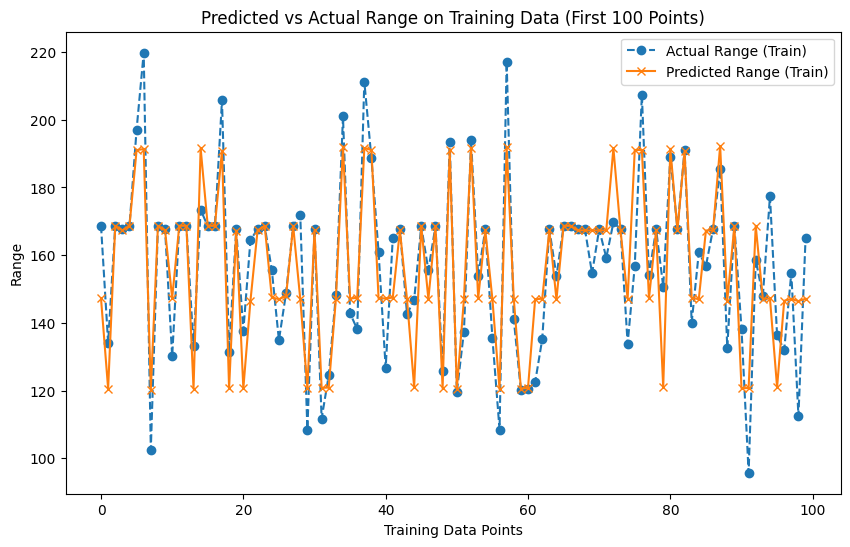

In [57]:
# -------------------------------
# Plot predicted vs. actual values for training data (first 100 points)
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

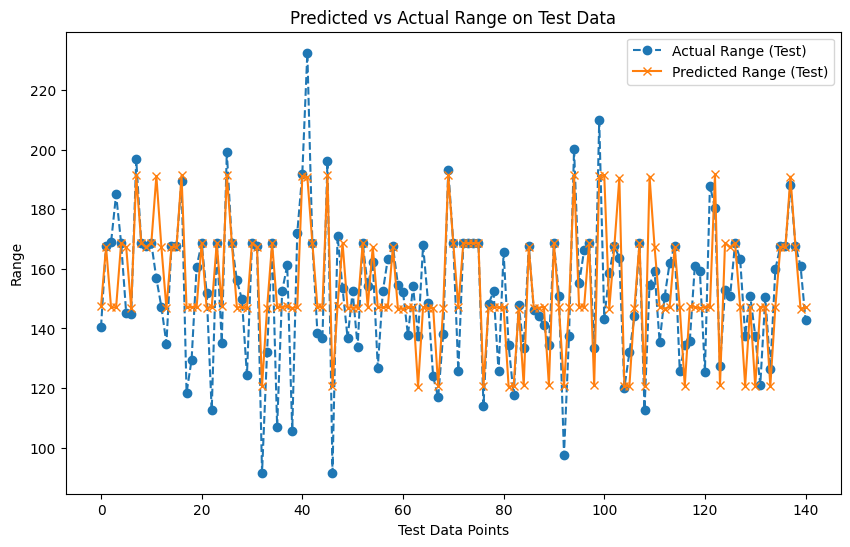

In [58]:
# -------------------------------
# Plot predicted vs. actual values for test data
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds, label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data')
plt.legend()
plt.show()

In [60]:
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args
from functools import partial

In [61]:
# Define the search space for x1, x2, x3, and x4
space = [
    Real(0.0, 1.0, name='x1'),  # x1 in [0, 1], rounded to 2 decimal places
    Real(0.0, 1.0, name='x2'),  # x2 in [0, 1], rounded to 2 decimal places
    Real(0.0, 1.0, name='x3'),  # x3 in [0, 1], rounded to 2 decimal places
    Real(0.0, 0.0001, name='x4')  # x4 in [0, 0.0001], with up to 6 decimal places
]

# Define the objective function for minimization
def objective_function(params, x5):
    x1, x2, x3, x4 = params
    # Use the rounded values of x1, x2, x3, and x4
    x1 = round(x1, 2)
    x2 = round(x2, 2)
    x3 = round(x3, 2)
    x4 = round(x4, 8)
    
    # Call the prediction function with the fixed x5 value
    return -predict_range(x1, x2, x3, x4, x5)  # Negative for maximization

# Initialize an empty dictionary to store the optimal results for each x5
optimal_results = {}

In [62]:
# Loop over each value of x5 from 0 to 6
for x5_value in range(7):  # x5 values from 0 to 6
    print(f"Optimizing for x5 = {x5_value}...")

    # Create a version of the objective function with fixed x5
    fixed_x5_function = partial(objective_function, x5=x5_value)
    
    # Run Bayesian Optimization with Expected Improvement
    result = gp_minimize(fixed_x5_function, space, n_calls=300, n_initial_points=20, acq_func='EI', random_state=42)
    
    # Extract the best result
    x1, x2, x3, x4 = result.x
    optimal_range = -result.fun  # Reverse the negative sign for maximization
    
    # Store the optimal results for this value of x5
    optimal_results[x5_value] = {
        "x1": round(x1, 2),
        "x2": round(x2, 2),
        "x3": round(x3, 2),
        "x4": round(x4, 6),
        "optimal_range": round(optimal_range, 2)
    }

# Print the optimal results for each x5 value
for x5_value, results in optimal_results.items():
    print(f"\nFor x5 = {x5_value}:")
    print(f"  Optimal inputs: x1={results['x1']:.2f}, x2={results['x2']:.2f}, x3={results['x3']:.2f}, x4={results['x4']:.6f}")
    print(f"  Maximum predicted range: {results['optimal_range']:.2f}")

Optimizing for x5 = 0...


Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:00<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:00<00:00]
Processing: 100%|██████████| [00:00<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:00<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:00<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing: 100%|██████████| [00:01<00:00]
Processing:

KeyboardInterrupt: 

Processing: 100%|██████████| [00:03<00:00]
